# 傅里叶：从频谱观察到滤波与通信

对应笔记：`../../../傅里叶.md`。所有数据在本地合成，无需下载。先运行准备单元，再按顺序运行；修改各节开头参数即可重复实验。

目标：用图像和数值验证公式，并理解公式能解决什么问题。数值验证只覆盖所选案例，不代替数学证明。

**绘图约定：** 离散序列、采样测量与 DFT/FFT 频点采用竖杆图，样本之间不连线；连续时间或连续频率模型用曲线。各分量与结果分开成图，子图标题说明角色。较长序列会展示注明范围的局部，计算仍使用完整数据。

**学习方法：** 每节先读“要理解什么”与数学等式，把公式左右两边对应到代码及子图，再看计算误差或反例。重点是解释公式；实际应用用于帮助理解。数值近似、有限案例、理论恒等式和广义函数极限在各节分别说明。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, integrate
from IPython.display import display, Markdown
rng = np.random.default_rng(42)
plt.rcParams.update({'figure.figsize': (9, 3), 'axes.grid': True})
# 图中使用英文标签，避免系统缺少中文字体；讲解和结果说明使用中文。
def graph(x, curves, xlabel='Sample index n', ylabel='Amplitude', *, kind='discrete', xlim=None):
    """每个分量独占子图；离散样本不连线，连续模型用曲线。"""
    import matplotlib.ticker as ticker
    count = len(curves)
    cols = min(2, count)
    rows = (count + cols - 1) // cols
    fig = plt.figure(figsize=(12 if cols == 2 else 10, 2.8 * rows), layout='constrained')
    grid = fig.add_gridspec(rows, cols)
    x = np.asarray(x)
    axes = []
    for i, (label, values) in enumerate(curves.items()):
        # 奇数个分量时，最后的结果图占满一行。
        slot = grid[i // cols, :] if count % 2 and i == count - 1 else grid[i // cols, i % cols]
        ax = fig.add_subplot(slot)
        values = np.asarray(values)
        color = f'C{i % 10}'
        if kind == 'discrete':
            marker, stems, baseline = ax.stem(x, values, basefmt='k-')
            plt.setp(marker, color=color, markersize=3 if len(x)>80 else 5)
            plt.setp(stems, color=color, linewidth=0.8 if len(x)>80 else 1.5)
            plt.setp(baseline, linewidth=0.5)
            if np.allclose(x, np.round(x)):
                ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=12, integer=True))
            if len(x) <= 20:
                ax.set_xticks(x)
                for xi, yi in zip(x, values):
                    if abs(yi) > max(1e-12, 0.05 * np.max(np.abs(values))):
                        ax.annotate(f'{yi:.3g}', (xi, yi), xytext=(0, 6 if yi >= 0 else -12),
                                    textcoords='offset points', ha='center', fontsize=8)
            ax.margins(y=0.2)
        elif kind == 'continuous':
            ax.plot(x, values, color=color, linewidth=1.5)
        else:
            raise ValueError('kind must be discrete or continuous')
        ax.set(title=label, xlabel=xlabel, ylabel=ylabel)
        if xlim is not None:
            ax.set_xlim(xlim)
        ax.grid(True, alpha=0.25)
        ax.set_axisbelow(True)
        axes.append(ax)
    plt.show()
    return axes

def err(a, b):
    return float(np.max(np.abs(np.asarray(a)-np.asarray(b))))


## 实验 1：欧拉公式、幅相与正负频率

**要理解什么：** 理解复指数怎样同时记录幅度与相位，以及实余弦为什么需要正负频率配对。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{e^{j\theta}=\cos\theta+j\sin\theta} \\[6pt]
\boxed{A\cos(\omega_0t+\theta)=\frac A2e^{j(\omega_0t+\theta)}+\frac A2e^{-j(\omega_0t+\theta)}}
\end{gathered}
$$

**符号与代码怎样对应：** `z=A*exp(1j*(w*t+theta))` 的实部是余弦、虚部是正弦；`(z+z.conj())/2` 把两条旋转方向相反的复指数相加。复平面圆图显示 z 的轨迹，不是时间横轴。

**怎样读图、怎样判断结果：** 正负频率项的虚部相互抵消，合成结果为实余弦，断言检查逐点相等；轨迹半径应为 A。打印的 A/2*exp(jθ) 是正频率复系数，不是原余弦的完整幅度 A。

**先预测，再改参数：** 改变 θ 观察起始相位，改变 A 观察圆半径及两频率系数大小。

**本例设置与适用范围：**

对应“傅里叶分析”第一节及性质第二节。$A\cos(\omega t+\theta)$ 由一对共轭的正负频率组成。

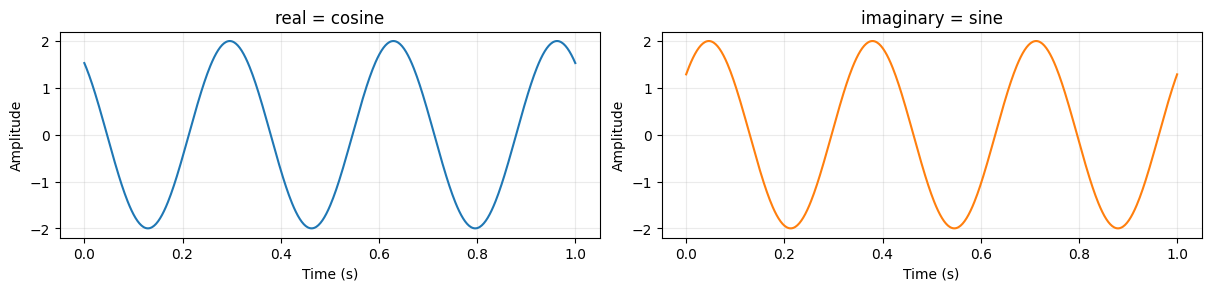

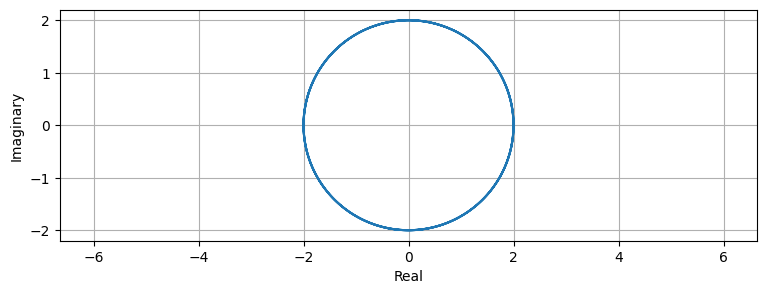

正频率复系数： (0.7648421872844885+0.644217687237691j)


In [2]:
A=2.; theta=0.7; t=np.linspace(0,1,500); w=2*np.pi*3
z=A*np.exp(1j*(w*t+theta)); recovered=(z+z.conj())/2
assert np.allclose(recovered.real,A*np.cos(w*t+theta))
graph(t,{'real = cosine':z.real,'imaginary = sine':z.imag},'Time (s)',kind='continuous')
plt.plot(z.real,z.imag); plt.axis('equal'); plt.xlabel('Real'); plt.ylabel('Imaginary'); plt.show()
print('正频率复系数：',A/2*np.exp(1j*theta))

**观察与应用：** 复指数把幅度与相位放在一个数中，适合相量计算、I/Q 通信。负频率不是额外一条真实声音，而是复数表示中与正频率配对的分量。

## 实验 2：正交性、系数归一化、直流与级数合成

**要理解什么：** 理解傅里叶系数是正交投影，合成是把各频率分量加回去。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{a_k=\frac1{T_0}\int_{T_0}\widetilde{x}(t)e^{-jk\omega_0t}\,dt} \\[6pt]
\boxed{\widetilde{x}(t)=\sum_{k=-\infty}^{+\infty}a_ke^{jk\omega_0t}} \\[6pt]
\omega_0=\frac{2\pi}{T_0}
\end{gathered}
$$

**符号与代码怎样对应：** `T` 对应 T0，`ks` 对应 k；`basis` 每列是一种复指数。`basis.conj().T@x/N` 用一周期样本均值近似系数积分，`basis@a` 是合成。Gram 矩阵检查归一化正交性。

**怎样读图、怎样判断结果：** 分量图为直流、基频、三次谐波，合起来等于原信号。此例 a0=1.5；非零频率系数只在 k=±1、±3，模分别为 1、0.35。重建和正交误差应接近零。

**先预测，再改参数：** 把直流 1.5 改成 0，预测只移除 k=0 谱线；更改三次谐波系数只影响 ±3 谱线。

**本例设置与适用范围：**

对应分析第二节。用一周期均匀采样平均近似 $a_k=T_0^{-1}\int x(t)e^{-jk\omega_0t}dt$。

正交 Gram 与单位阵误差： 2.220446049250313e-16
a0 与时间平均值： (1.5+0j) 1.4999999999999998 重建误差： 2.6645352591003757e-15


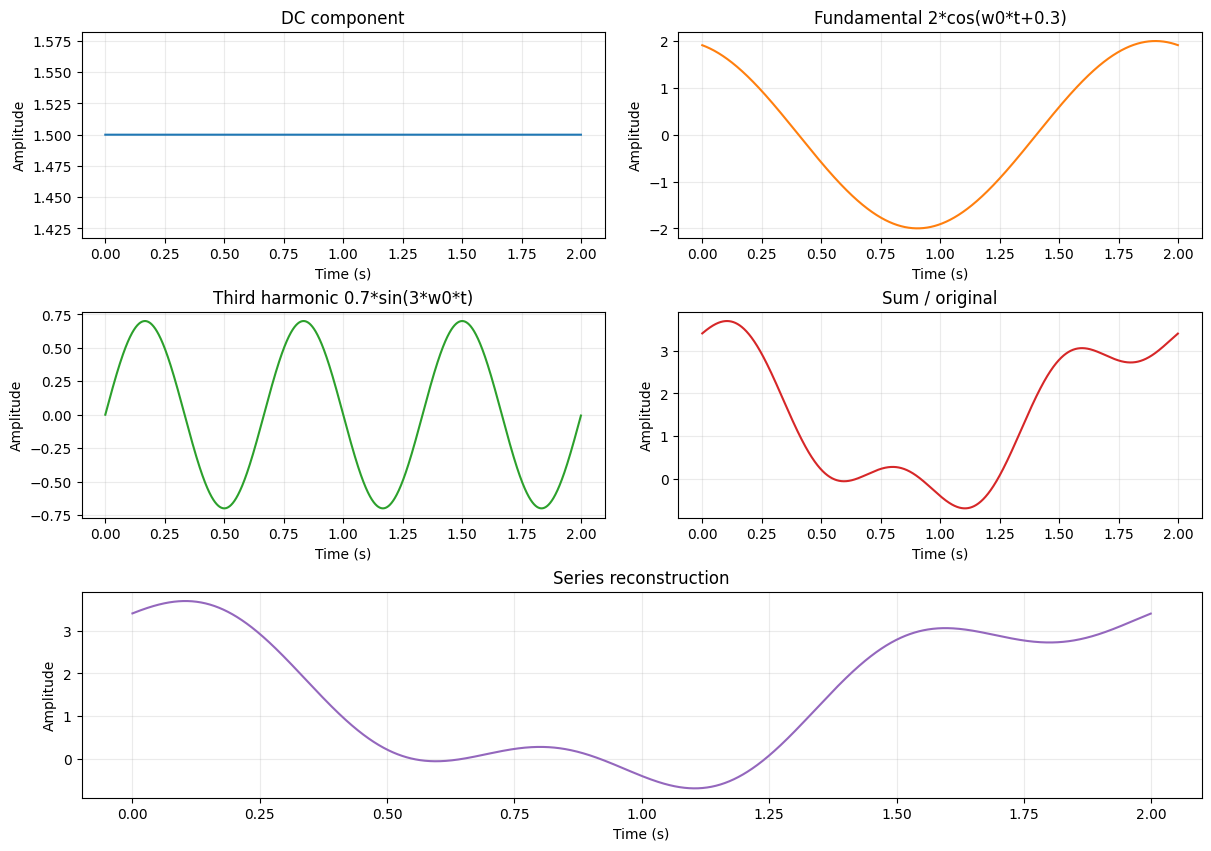

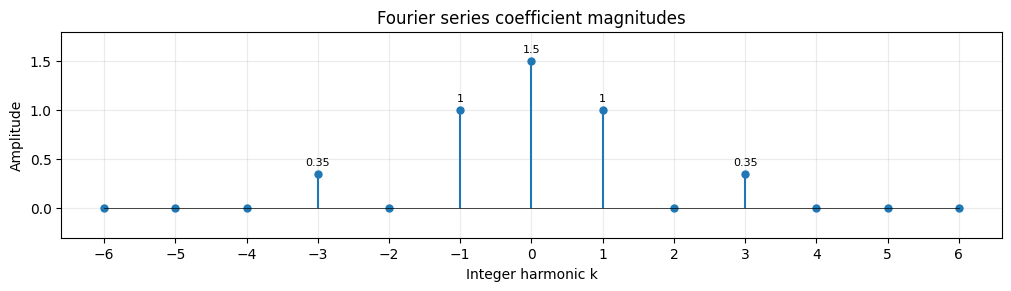

[<Axes: title={'center': 'Fourier series coefficient magnitudes'}, xlabel='Integer harmonic k', ylabel='Amplitude'>]

In [3]:
T=2.; N=2048; t=np.arange(N)*T/N; w0=2*np.pi/T
x=1.5+2*np.cos(w0*t+0.3)+0.7*np.sin(3*w0*t)
ks=np.arange(-6,7); basis=np.exp(1j*np.outer(t,ks*w0))
a=basis.conj().T@x/N; recovered=(basis@a).real
gram=basis.conj().T@basis/N
print('正交 Gram 与单位阵误差：',err(gram,np.eye(len(ks))))
print('a0 与时间平均值：',a[ks==0][0],x.mean(),'重建误差：',err(x,recovered))
assert np.allclose(x,recovered)
graph(t,{'DC component':np.full_like(t,1.5),
    'Fundamental 2*cos(w0*t+0.3)':2*np.cos(w0*t+0.3),
    'Third harmonic 0.7*sin(3*w0*t)':0.7*np.sin(3*w0*t),
    'Sum / original':x,'Series reconstruction':recovered},'Time (s)',kind='continuous')
graph(ks,{'Fourier series coefficient magnitudes':abs(a)},'Integer harmonic k',kind='discrete')

**观察与应用：** a0 是直流偏置，可用来发现传感器零点偏移；正交投影能分离不同谐波，用于振动故障诊断。

## 实验 3：实值奇偶性、正负频率合并与方波谐波

**要理解什么：** 理解奇偶对称为何决定只需余弦或正弦，以及有限谐波怎样逼近方波。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{x_{\mathrm{even}}(t)=a_0+2\sum_{k=1}^{\infty}a_k\cos(k\omega_0t)} \\[6pt]
\boxed{x_{\mathrm{odd}}(t)=2j\sum_{k=1}^{\infty}a_k\sin(k\omega_0t)}
\end{gathered}
$$

**符号与代码怎样对应：** 前半段数值投影偶信号与奇信号，分别检查系数虚部和实部。方波部分使用由系数公式得到的正弦级数 (4/π)Σ sin(2πkt)/k，其中 k 为正奇数；`M` 是保留的奇次谐波数量。

**怎样读图、怎样判断结果：** 偶信号系数虚部接近零，奇信号系数实部接近零。分量图显示前几次谐波；增加 M 后合成边沿更陡，但跳变附近仍有 Gibbs 超调，跳变点按左右极限平均理解。

**先预测，再改参数：** 只保留基频，再逐次加入 3、5 次谐波，先预测波形形状再查看。

**本例设置与适用范围：**

对应分析第三节。偶信号系数为实数，奇信号为纯虚数。方波用有限奇次正弦谐波近似。

even 最大实部 0.5000000000000001 最大虚部 8.326672684688674e-17
odd 最大实部 5.551115123125783e-17 最大虚部 0.5


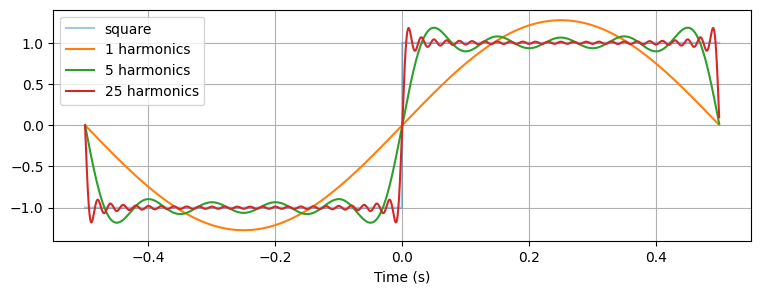

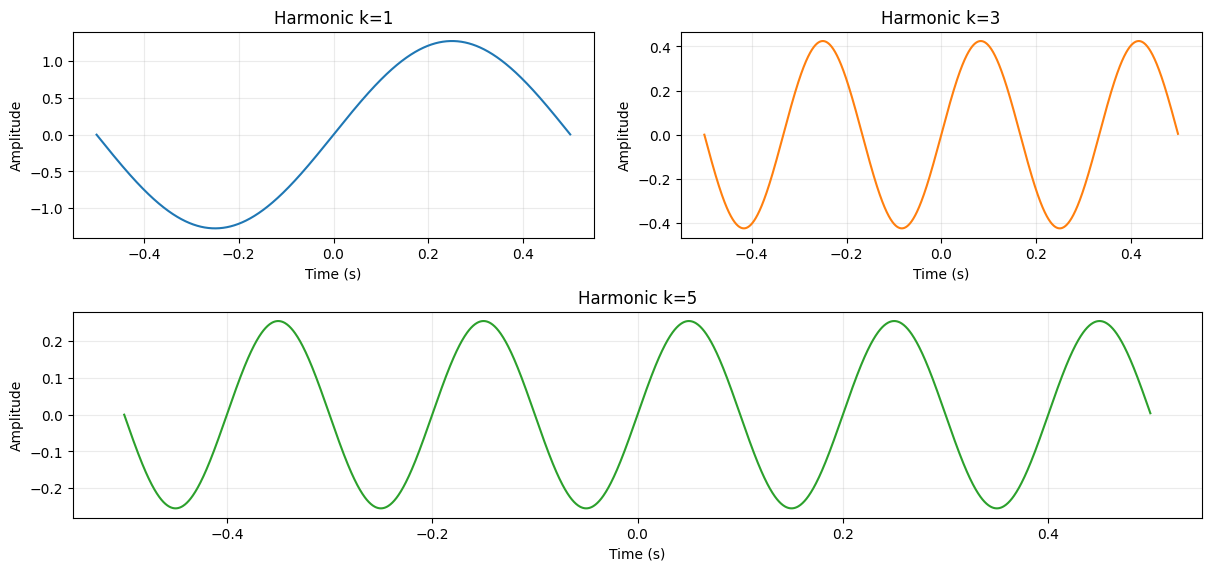

[<Axes: title={'center': 'Harmonic k=1'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Harmonic k=3'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Harmonic k=5'}, xlabel='Time (s)', ylabel='Amplitude'>]

In [4]:
N=2048; t=np.arange(N)/N-0.5; ks=np.arange(-8,9)
B=np.exp(-2j*np.pi*np.outer(ks,t))
for name,x in {'even':np.cos(2*np.pi*t)+0.2*np.cos(4*np.pi*t),
               'odd':np.sin(2*np.pi*t)}.items():
    a=B@x/N
    print(name,'最大实部',max(abs(a.real)),'最大虚部',max(abs(a.imag)))
x=signal.square(2*np.pi*t)
plt.plot(t,x,label='square',alpha=0.4)
for M in [1,5,25]:
    odds=np.arange(1,2*M,2)
    y=np.sum(4/np.pi*np.sin(2*np.pi*np.outer(t,odds))/odds,axis=1)
    plt.plot(t,y,label=f'{M} harmonics')
plt.legend(); plt.xlabel('Time (s)'); plt.show()
first_odds=np.array([1,3,5])
graph(t,{f'Harmonic k={k}':4/(np.pi*k)*np.sin(2*np.pi*k*t) for k in first_odds},
    'Time (s)',kind='continuous')

**观察与应用：** 谐波越多，方波边沿越陡，但跳变附近仍有 Gibbs 超调，不能指望增加谐波消除峰值超调。可解释数字脉冲带宽和音色。

## 实验 4：级数到变换、频谱包络与脉宽测量

**要理解什么：** 理解周期谱线为什么落在单个脉冲的频谱包络上，以及零点怎样反映脉宽。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{T_0a_k=X(k\omega_0)},\quad\boxed{\Delta\omega=\frac{2\pi}{T_0}} \\[6pt]
\boxed{X(\omega)=\tau\frac{\sin(\omega\tau/2)}{\omega\tau/2}},\quad\boxed{\omega_1=\frac{2\pi}{\tau}}
\end{gathered}
$$

**符号与代码怎样对应：** `tau` 是单个矩形脉冲宽度，`T` 是重复周期 T0；`wk` 是谱线位置。连续曲线是 |X|，竖杆是 T0|ak|，必须经过 T0 缩放才直接与包络比较。`np.sinc(z)` 按 sin(πz)/(πz) 定义。

**怎样读图、怎样判断结果：** 改变 T 使谱线间距变化，包络保持不变；竖杆顶端在曲线上。独立积分算出的 T0*ak 应与 X(kω0) 接近。tau=0.4 时第一正零点约 15.708 rad/s。

**先预测，再改参数：** 把 tau 减半，预测第一零点加倍；这就是更短脉冲需要更宽频带。

**本例设置与适用范围：**

对应分析第四、五节。矩形脉冲 $X(\omega)=\tau\,\mathrm{sinc}(\omega\tau/(2\pi))$，$T_0a_k=X(k\omega_0)$。np.sinc 的定义是 sin(pi x)/(pi x)。

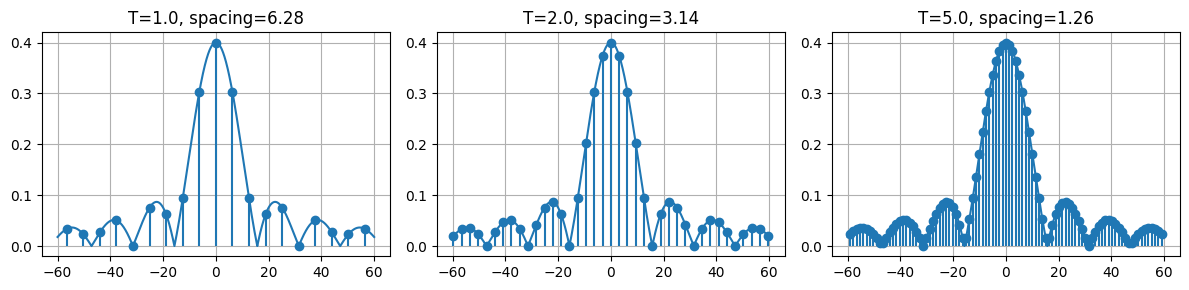

第一个正零点 rad/s： 15.707963267948966 由零点反推宽度 s： 0.4
数值系数与包络取样误差： 1.8673951274195133e-09


In [5]:
tau=0.4; w=np.linspace(-60,60,3000)
X=lambda ww:tau*np.sinc(ww*tau/(2*np.pi))
fig,axes=plt.subplots(1,3,figsize=(12,3))
for T,ax in zip([1.,2.,5.],axes):
    k=np.arange(-int(60*T/(2*np.pi)),int(60*T/(2*np.pi))+1); wk=2*np.pi*k/T
    ak=X(wk)/T
    ax.plot(w,abs(X(w)),label='single pulse envelope')
    ax.stem(wk,T*abs(ak),basefmt=' '); ax.set_title(f'T={T}, spacing={2*np.pi/T:.2f}')
plt.tight_layout(); plt.show()
w1=2*np.pi/tau
print('第一个正零点 rad/s：',w1,'由零点反推宽度 s：',2*np.pi/w1)
# 独立数值积分验证一个周期内的系数。
T=2.; tt=(np.arange(40000)+0.5)*T/40000-T/2; k=3
ak_num=np.mean((abs(tt)<tau/2)*np.exp(-1j*k*2*np.pi/T*tt))
print('数值系数与包络取样误差：',abs(T*ak_num-X(k*2*np.pi/T)))

**观察与应用：** 增大重复周期会使谱线变密，而单个脉冲的包络不变。脉冲越窄，第一零点越远，可估计雷达或数字脉冲所需带宽；真实脉冲非矩形时不能直接用零点公式。

## 实验 5：变换、逆变换与 1/(2pi)

**要理解什么：** 理解分析与合成是一对逆运算，并确认角频率约定中的归一化系数。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{X(\omega)=\int_{-\infty}^{+\infty}x(t)e^{-j\omega t}\,dt} \\[6pt]
\boxed{x(t)=\frac1{2\pi}\int_{-\infty}^{+\infty}X(\omega)e^{j\omega t}\,d\omega}
\end{gathered}
$$

**符号与代码怎样对应：** 本例选择已知变换对 x(t)=exp(−t²/2)、X(ω)=√(2π)exp(−ω²/2)。`trapezoid(...,w)` 近似逆变换积分，`/(2*pi)` 对应笔记系数；以解析原信号作为独立参考。

**怎样读图、怎样判断结果：** 重建曲线应等于原高斯，误差应小于断言容差。有限频率区间能有效截断是因为高斯尾部已很小，不能认为所有信号都可用同一区间。

**先预测，再改参数：** 去掉 1/(2π)，预测重建幅度整体乘 2π；缩小频率区间，观察截断误差。

**本例设置与适用范围：**

对应分析第六节、性质第二节。对高斯 $x=e^{-t^2/2}$，$X=\sqrt{2\pi}e^{-\omega^2/2}$，用角频率积分直接重建。

重建最大误差： 2.8867625499877686e-15


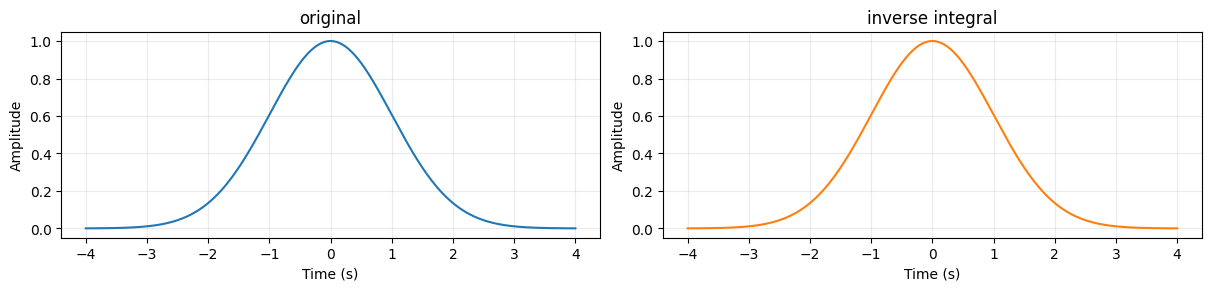

[<Axes: title={'center': 'original'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'inverse integral'}, xlabel='Time (s)', ylabel='Amplitude'>]

In [6]:
t=np.linspace(-4,4,301); w=np.linspace(-12,12,2401)
X=np.sqrt(2*np.pi)*np.exp(-w*w/2)
y=integrate.trapezoid(X[:,None]*np.exp(1j*w[:,None]*t),w,axis=0)/(2*np.pi)
print('重建最大误差：',err(y,np.exp(-t*t/2)))
assert np.allclose(y.real,np.exp(-t*t/2),atol=1e-8)
graph(t,{'original':np.exp(-t*t/2),'inverse integral':y.real},'Time (s)',kind='continuous')

**观察与应用：** 可以用频谱重建信号。删除逆变换中的 1/(2pi) 后振幅会整体放大 2pi；若使用 Hz 频率，公式则采用 exp(j2pi ft)，归一化约定不能混搭。

## 实验 6：指数衰减、幅相与 -3 dB

**要理解什么：** 理解指数衰减参数如何决定直流幅度、频谱相位与截止位置。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{e^{-at}u(t)\xleftrightarrow{\mathcal F}\frac1{a+j\omega}},\quad a>0 \\[6pt]
\boxed{|X(\omega)|=\frac1{\sqrt{a^2+\omega^2}}},\quad\boxed{\angle X(\omega)=-\arctan(\omega/a)} \\[6pt]
\frac{|X(a)|}{|X(0)|}=\frac1{\sqrt2}
\end{gathered}
$$

**符号与代码怎样对应：** `X=1/(a+1j*w)` 是解析频谱；幅度图除以直流 1/a 再换算 dB，因此比较的是相对下降。后半段对指数积分独立检验变换对。时间常数 τ=1/a。

**怎样读图、怎样判断结果：** ω=a 时相对幅度约 −3.01 dB，相位为 −π/4；不同 a 曲线的截止点随之变化，τ*ωc=1。正频率截止点是 a，全宽为 2a。

**先预测，再改参数：** 增大 a，先预测时间衰减更快但相对频谱更宽、直流幅度更小。

**本例设置与适用范围：**

对应分析第七节、尺度示例。$X=1/(a+j\omega)$，$\tau=1/a$，$\omega_c=a$。

a=0.5: DC=2.000, cutoff=0.5, tau*cutoff=1.0, cutoff dB=-3.010


a=1.0: DC=1.000, cutoff=1.0, tau*cutoff=1.0, cutoff dB=-3.010
a=3.0: DC=0.333, cutoff=3.0, tau*cutoff=1.0, cutoff dB=-3.010


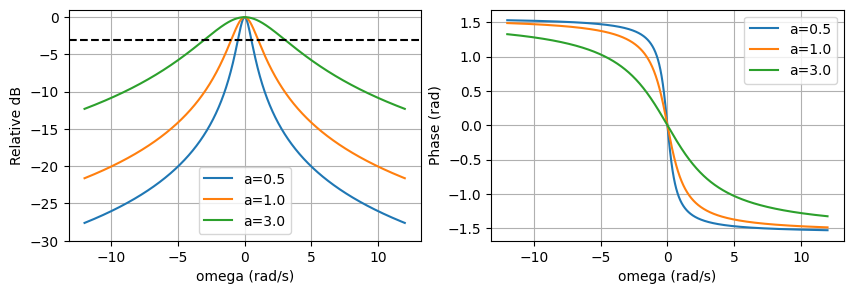

积分与解析式误差： 2.635253902070193e-07


In [7]:
w=np.linspace(-12,12,1601)
fig,axes=plt.subplots(1,2,figsize=(10,3))
for a in [0.5,1.,3.]:
    X=1/(a+1j*w)
    axes[0].plot(w,20*np.log10(abs(X)/(1/a)),label=f'a={a}')
    axes[1].plot(w,np.angle(X),label=f'a={a}')
    print(f'a={a}: DC={1/a:.3f}, cutoff={a}, tau*cutoff={(1/a)*a}, cutoff dB={20*np.log10(1/np.sqrt(2)):.3f}')
axes[0].axhline(-3.0103,color='k',ls='--'); axes[0].set(ylim=(-30,1),xlabel='omega (rad/s)',ylabel='Relative dB')
axes[1].set(xlabel='omega (rad/s)',ylabel='Phase (rad)')
for ax in axes: ax.legend()
plt.show()
a=1.; tt=np.linspace(0,25,25001); wt=np.array([0.,1.,3.])
num=integrate.trapezoid(np.exp(-(a+1j*wt[:,None])*tt),tt,axis=1)
print('积分与解析式误差：',err(num,1/(a+1j*wt)))

**观察与应用：** 一阶低通的时间常数与截止角频率互为倒数；更快的响应需要更宽频带。这里 -3 dB 全宽为 2a，工程低通常说的正频率截止点是 a。

## 实验 7：时间尺度、负尺度与带宽

**要理解什么：** 理解时间压缩、扩展与反转如何映射到频谱，而不只记住一句“时窄频宽”。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{x(at)\xleftrightarrow{\mathcal F}\frac1{|a|}X\left(\frac{\omega}{a}\right)},\quad a\ne0
\end{gathered}
$$

**符号与代码怎样对应：** `a` 是尺度参数，本节不再是指数衰减率。原信号取偏移高斯 x(t)=exp(−(t−1)²/2)，`num` 直接积分 x(at)，`theory=Xbase(w/a)/abs(a)` 是性质预测，比较完整复数值而非只比较模。

**怎样读图、怎样判断结果：** a=2 的时域宽度减半、频谱展宽，a=0.5 相反；a=−2 还会把中心反转到负时间。打印复频谱误差应小，有限积分截断会留下少量误差。

**先预测，再改参数：** 把理论式误写为 1/a，观察负尺度时符号错误；然后恢复绝对值。

**本例设置与适用范围：**

对应分析八及性质四。$x(at)\leftrightarrow |a|^{-1}X(\omega/a)$。使用偏移高斯，使负尺度引起的时间反转也可见。

尺度 0.5 复频谱最大误差： 0.00015878240441402625


尺度 2.0 复频谱最大误差： 4.742874840267547e-16


尺度 -2.0 复频谱最大误差： 5.661048867003677e-16


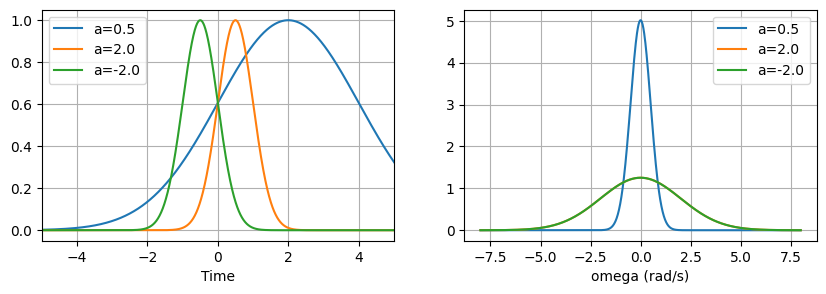

In [8]:
t=np.linspace(-10,10,4001); w=np.linspace(-8,8,801)
def Xbase(w): return np.sqrt(2*np.pi)*np.exp(-w*w/2)*np.exp(-1j*w)
fig,axes=plt.subplots(1,2,figsize=(10,3))
for a in [0.5,2.,-2.]:
    x=np.exp(-(a*t-1)**2/2)
    num=integrate.trapezoid(x[None,:]*np.exp(-1j*w[:,None]*t),t,axis=1)
    theory=Xbase(w/a)/abs(a)
    print('尺度',a,'复频谱最大误差：',err(num,theory))
    axes[0].plot(t,x,label=f'a={a}'); axes[1].plot(w,abs(num),label=f'a={a}')
for ax in axes: ax.legend()
axes[0].set(xlim=(-5,5),xlabel='Time'); axes[1].set(xlabel='omega (rad/s)'); plt.show()

**观察与应用：** 压缩时间会扩展带宽并改变频谱幅度；负尺度还会反转时间。适合解释加速播放时的频率升高和短脉冲对宽带设备的需求。

## 实验 8：时间平移：幅度相同，相位携带延迟

**要理解什么：** 理解延迟信息藏在相位中，幅度谱相同并不代表到达时间相同。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{x(t-t_0)\xleftrightarrow{\mathcal F}e^{-j\omega t_0}X(\omega)} \\[6pt]
 |Y(\omega)|=|X(\omega)|,\quad\angle Y(\omega)\equiv\angle X(\omega)-\omega t_0\pmod{2\pi}
\end{gathered}
$$

**符号与代码怎样对应：** `Xd` 由延迟高斯直接积分，`X` 是未延迟高斯的解析谱。`angle(Xd/X)` 提取相对相位，`unwrap` 消除 2π 跳变，`polyfit` 拟合斜率；仅用幅度不太小的频段。

**怎样读图、怎样判断结果：** 相对相位应近似直线 −ωt0；负斜率的相反数应恢复 t0=1.3，幅度差应很小。频谱为零处相位没有定义，不能用于估计。

**先预测，再改参数：** 把 t0 改为负数，预测相位斜率变正，表示信号提前。

**本例设置与适用范围：**

对应分析八、性质七。用高斯脉冲直接积分，检验 $X_d=e^{-j\omega t_0}X$，仅在幅度足够处拟合相位斜率。

幅度误差： 1.3322676295501878e-15 相位估计延迟： 1.3000000000000007 真实延迟： 1.3


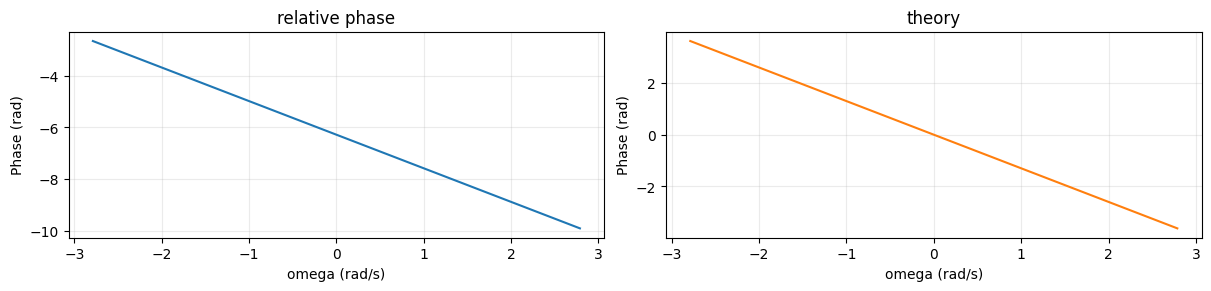

[<Axes: title={'center': 'relative phase'}, xlabel='omega (rad/s)', ylabel='Phase (rad)'>,
 <Axes: title={'center': 'theory'}, xlabel='omega (rad/s)', ylabel='Phase (rad)'>]

In [9]:
t=np.linspace(-10,10,4001); w=np.linspace(-5,5,801); t0=1.3
X=np.sqrt(2*np.pi)*np.exp(-w*w/2)
xd=np.exp(-(t-t0)**2/2)
Xd=integrate.trapezoid(xd[None,:]*np.exp(-1j*w[:,None]*t),t,axis=1)
mask=X>0.02*max(X); phase=np.unwrap(np.angle(Xd[mask]/X[mask]))
slope=np.polyfit(w[mask],phase,1)[0]
print('幅度误差：',err(abs(Xd),X),'相位估计延迟：',-slope,'真实延迟：',t0)
graph(w[mask],{'relative phase':phase,'theory':-w[mask]*t0},'omega (rad/s)','Phase (rad)',kind='continuous')

**观察与应用：** 幅度谱看不出信号到达时间；相位斜率能估计传播延迟，用于声学测距与设备同步。频谱接近零时相位不可靠，应排除这些点。

## 实验 9：实信号的共轭对称与半谱存储

**要理解什么：** 理解实信号的负频率并不独立，为什么只保存半谱就可恢复。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{X(-\omega)=X^*(\omega)} \\[6pt]
\operatorname{Re}X(-\omega)=\operatorname{Re}X(\omega),\quad\operatorname{Im}X(-\omega)=-\operatorname{Im}X(\omega),\quad |X(-\omega)|=|X(\omega)|
\end{gathered}
$$

**符号与代码怎样对应：** 代码用实值随机序列作离散对应验证；DFT 中负频率编号是 (−k) mod N，`neg` 执行此映射。相位相加后取模 2π，避免把 ±π 的表示差当作错误。`rfft/irfft` 检查半谱重建。

**怎样读图、怎样判断结果：** 共轭、实部、虚部、模和相位的误差均应接近零；N=1024 时半谱有 513 个复数值，重建仍应恢复全部 1024 个实样本。

**先预测，再改参数：** 把输入改为实随机数+1j*另一组随机数，预测共轭对称不再成立；此时不能继续用 rfft。

**本例设置与适用范围：**

对应分析八、性质三。验证实部偶、虚部奇、幅度偶、相位模 $2\pi$ 反号；DFT 的负频率索引为 $(-k)\bmod N$。

In [10]:
N=1024; x=rng.normal(size=N); X=np.fft.fft(x); neg=(-np.arange(N))%N
print('共轭、实部偶、虚部奇、幅度偶误差：',err(X[neg],X.conj()),err(X[neg].real,X.real),err(X[neg].imag,-X.imag),err(abs(X[neg]),abs(X)))
phase_error=np.angle(np.exp(1j*(np.angle(X[neg])+np.angle(X))))
print('相位模 2pi 误差：',max(abs(phase_error)))
half=np.fft.rfft(x); recovered=np.fft.irfft(half,n=N)
assert np.allclose(recovered,x)
print('全谱/半谱复数个数：',len(X),len(half),'恢复误差：',err(x,recovered))

共轭、实部偶、虚部奇、幅度偶误差： 2.3898437090739065e-14 2.2870594307278225e-14 2.1316282072803006e-14 2.842170943040401e-14
相位模 2pi 误差： 5.218048215738236e-15
全谱/半谱复数个数： 1024 513 恢复误差： 9.992007221626409e-16


**观察与应用：** 实信号的负频率可从正频率恢复，音频和传感器频谱可用 rfft 节省存储。复数 I/Q 信号通常不满足这种对称性。

## 实验 10：对偶性与时间反转

**要理解什么：** 理解对偶性中的交换角色、时间反转和 2π 系数。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
x(t)\xleftrightarrow{\mathcal F}X(\omega)\quad\Longrightarrow\quad\boxed{X(t)\xleftrightarrow{\mathcal F}2\pi x(-\omega)}
\end{gathered}
$$

**符号与代码怎样对应：** 以偏移高斯为原 x，其频谱表达式改用 t 作自变量生成 `Xt`。`dual` 直接求这个新函数的变换，`theory` 为 2π*x(−w)。这里 X(t) 是重新使用函数表达式，不是把时间单位改成角频率单位。

**怎样读图、怎样判断结果：** 两图应相等且峰出现在 −shift 处；误差满足断言。使用偏移高斯是为了让负号的作用可见，偶函数会掩盖反转。

**先预测，再改参数：** 去掉理论式中的反号，预测两图峰值位置不同；再恢复。

**本例设置与适用范围：**

对应性质第五节。若 $x(t)\leftrightarrow X(\omega)$，则 $X(t)\leftrightarrow2\pi x(-\omega)$。用非对称的偏移高斯验证负号。

对偶性误差： 1.7772239894833365e-15


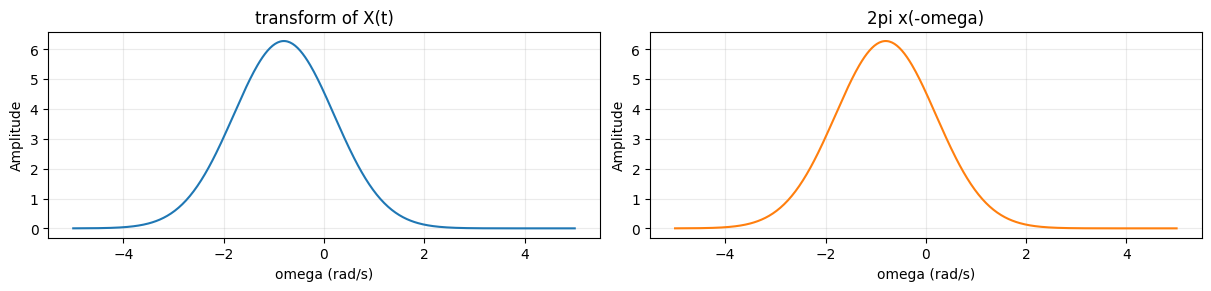

[<Axes: title={'center': 'transform of X(t)'}, xlabel='omega (rad/s)', ylabel='Amplitude'>,
 <Axes: title={'center': '2pi x(-omega)'}, xlabel='omega (rad/s)', ylabel='Amplitude'>]

In [11]:
t=np.linspace(-10,10,4001); w=np.linspace(-5,5,401); shift=0.8
Xt=np.sqrt(2*np.pi)*np.exp(-t*t/2)*np.exp(-1j*t*shift)
dual=integrate.trapezoid(Xt[None,:]*np.exp(-1j*w[:,None]*t),t,axis=1)
theory=2*np.pi*np.exp(-(-w-shift)**2/2)
print('对偶性误差：',err(dual,theory))
assert np.allclose(dual.real,theory,atol=1e-8)
graph(w,{'transform of X(t)':dual.real,'2pi x(-omega)':theory},'omega (rad/s)',kind='continuous')

**观察与应用：** 已知一组变换对，就能交换时频角色得到另一组，减少重复积分。偏移高斯可清楚显示反转；偶高斯会掩盖公式中的负号。

## 实验 11：帕塞瓦尔：能量与周期平均功率

**要理解什么：** 理解时域与频域是同一信号的两种表示，能量或平均功率应一致。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{\int_{-\infty}^{+\infty}|x(t)|^2dt=\frac1{2\pi}\int_{-\infty}^{+\infty}|X(\omega)|^2d\omega} \\[6pt]
\boxed{\frac1{T_0}\int_{T_0}|\widetilde{x}(t)|^2dt=\sum_{k=-\infty}^{+\infty}|a_k|^2}
\end{gathered}
$$

**符号与代码怎样对应：** `Et,Ef` 分别按两边积分计算高斯能量；`periodic` 为另一条周期信号，`a=fft(periodic)/N` 估计其级数系数，样本均值对应一周期平均功率。

**怎样读图、怎样判断结果：** 高斯两侧能量约 √π；周期信号平均功率应为 1.5²+2²/2+0.7²/2=4.495。柱状图比较的是前者能量，不是后者功率；周期非零信号通常不能套用有限总能量结论。

**先预测，再改参数：** 将三次谐波幅度 0.7 改为 1，预测平均功率增加 (1−0.7²)/2。

**本例设置与适用范围：**

对应性质第六节。连续能量 $\int|x|^2dt=(2\pi)^{-1}\int|X|^2d\omega$；周期平均功率为 $\sum|a_k|^2$。

连续时域/频域能量： 1.7724538509055159 1.7724538509055159
周期时均功率/系数功率： 4.494999999999999 4.495


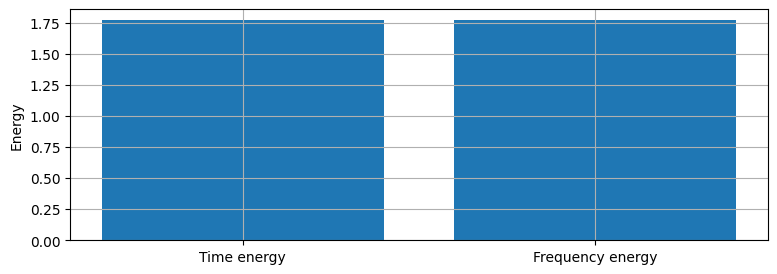

In [12]:
t=np.linspace(-8,8,8001); w=np.linspace(-10,10,10001)
x=np.exp(-t*t/2); X=np.sqrt(2*np.pi)*np.exp(-w*w/2)
Et=integrate.trapezoid(abs(x)**2,t); Ef=integrate.trapezoid(abs(X)**2,w)/(2*np.pi)
print('连续时域/频域能量：',Et,Ef)
N=2048; tt=np.arange(N)/N; periodic=1.5+2*np.cos(2*np.pi*tt)+0.7*np.sin(6*np.pi*tt)
a=np.fft.fft(periodic)/N
print('周期时均功率/系数功率：',np.mean(periodic**2),np.sum(abs(a)**2))
assert np.isclose(Et,Ef) and np.isclose(np.mean(periodic**2),np.sum(abs(a)**2))
plt.bar(['Time energy','Frequency energy'],[Et,Ef]); plt.ylabel('Energy'); plt.show()

**观察与应用：** 不用重建完整波形也能计算频带能量或评估滤波保留多少能量。周期信号一般总能量无限，应比较平均功率，不能把两类公式混用。

## 实验 12：线性、微分与积分：速度、位移和噪声

**要理解什么：** 理解微分强调高频、积分须处理常数，并用已知导数检验频域计算。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{\frac{dx(t)}{dt}\xleftrightarrow{\mathcal F}j\omega X(\omega)} \\[6pt]
\boxed{Y(\omega)=\operatorname{PV}\frac{X(\omega)}{j\omega}+\pi X(0)\delta(\omega)}\quad\left(y(t)=\int_{-\infty}^{t}x(\tau)d\tau\right) \\[6pt]
\boxed{\mathcal F\{ax_1+bx_2\}=aX_1+bX_2}
\end{gathered}
$$

**符号与代码怎样对应：** 本代码使用有限个谐波的周期信号与 DFT 作谱微分，不直接数值实现广义函数积分公式。`1j*w*X` 作用于每个谐波；非零频率除以 1j*w 后，零频率置零并用初值补积分常数，得到周期原函数。`exact` 和 `expected` 是逐项求导/积分的独立解析答案。

**怎样读图、怎样判断结果：** 导数与原函数误差应接近零，线性误差应接近零；微分噪声分量加回导数后明显抖动。一般从负无穷积分的公式需要主值与零频率项，本周期例子只验证非零谐波关系及初值处理，不是对一般积分公式的完整验证。

**先预测，再改参数：** 增加高频噪声，预测求导后影响更强；输入带直流偏置时原函数会有线性漂移，不能用周期零频率置零掩盖它。

**本例设置与适用范围：**

对应性质第八节。周期平滑信号微分对应 $j\omega X$；零均值信号可对非零频率除以 $j\omega$ 积分。一般从负无穷积分的公式还含 $\pi X(0)\delta(\omega)$ 与主值项，不能一律直接除零频。

微分/积分误差： 2.950528710243816e-12 1.942890293094024e-16
线性误差： 8.853992992873203e-14
输入噪声标准差/求导后： 0.01016692491612578 9.591045925073727


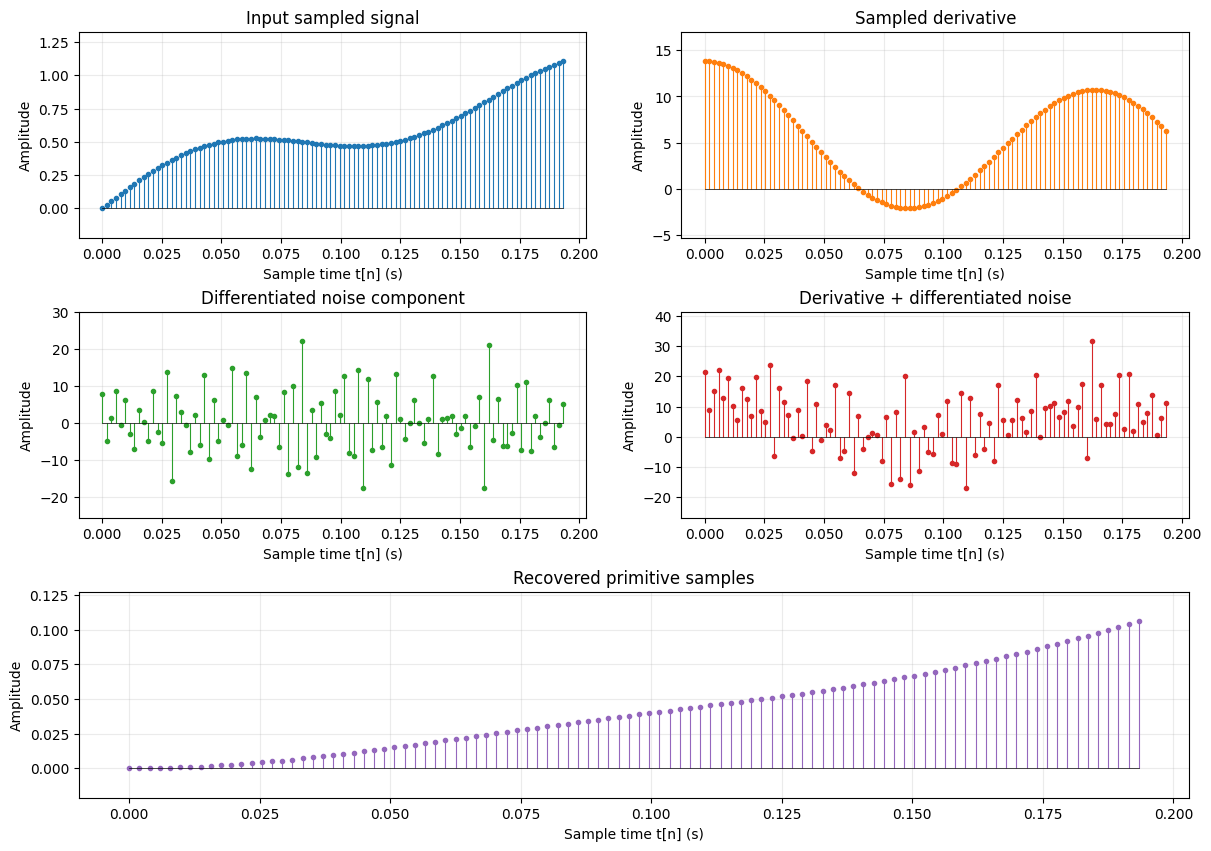

积分偏置示例：常值偏置 0.02，10秒后漂移为 0.2


In [13]:
N=1024; T=2.; t=np.arange(N)*T/N; w=2*np.pi*np.fft.fftfreq(N,d=T/N)
x=np.sin(2*np.pi*t)+0.2*np.sin(12*np.pi*t)
X=np.fft.fft(x); derivative=np.fft.ifft(1j*w*X).real
exact=2*np.pi*np.cos(2*np.pi*t)+0.2*12*np.pi*np.cos(12*np.pi*t)
assert np.allclose(derivative,exact,atol=1e-9)
Y=np.zeros(N,complex); nonzero=w!=0; Y[nonzero]=X[nonzero]/(1j*w[nonzero])
primitive=np.fft.ifft(Y).real; primitive-=primitive[0]
expected=(1-np.cos(2*np.pi*t))/(2*np.pi)+0.2*(1-np.cos(12*np.pi*t))/(12*np.pi)
print('微分/积分误差：',err(derivative,exact),err(primitive,expected))
print('线性误差：',err(np.fft.fft(2*x+3*x*x),2*X+3*np.fft.fft(x*x)))
noise=0.01*rng.normal(size=N)
dnoise=np.fft.ifft(1j*w*np.fft.fft(noise)).real
print('输入噪声标准差/求导后：',noise.std(),dnoise.std())
graph(t[:100],{'Input sampled signal':x[:100],'Sampled derivative':derivative[:100],
    'Differentiated noise component':dnoise[:100],
    'Derivative + differentiated noise':(derivative+dnoise)[:100],
    'Recovered primitive samples':primitive[:100]},'Sample time t[n] (s)',kind='discrete')
print('积分偏置示例：常值偏置 0.02，10秒后漂移为',0.02*10)

**观察与应用：** 求导能突出边缘、速度变化，也会放大高频噪声；积分可从速度算位移，但未知常数和直流偏置会造成漂移。本实验除频率法仅用于零均值周期数据，积分常数通过初值补齐。

## 实验 13：调制与频移：把低频消息搬到载波

**要理解什么：** 理解调制将频率整体平移，实载波为什么产生两个边带。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{x(t)e^{j\omega_ct}\xleftrightarrow{\mathcal F}X(\omega-\omega_c)} \\[6pt]
 x(t)\cos(\omega_ct)\xleftrightarrow{\mathcal F}\frac12[X(\omega-\omega_c)+X(\omega+\omega_c)]
\end{gathered}
$$

**符号与代码怎样对应：** `message` 是 10Hz 与 20Hz 两分量之和；`complex_mod` 乘复指数，`real_mod` 乘实余弦。代码用 Hz 显示 FFT 频点，故载波对应 ωc=2πfc，取 fc=150Hz。

**怎样读图、怎样判断结果：** 原消息谱线在 ±10、±20Hz；复调制移到 130、140、160、170Hz；实调制在正负载波两侧都有谱线，分量系数减半。乘反向复指数应恢复原消息。

**先预测，再改参数：** 把 fc 改为 200Hz（保持奈奎斯特范围内），预测谱线整体位置。

**本例设置与适用范围：**

对应分析八。复调制 $x(t)e^{j\omega_ct}$ 平移一次；实余弦调制产生左右两个频带，各有 1/2 系数。

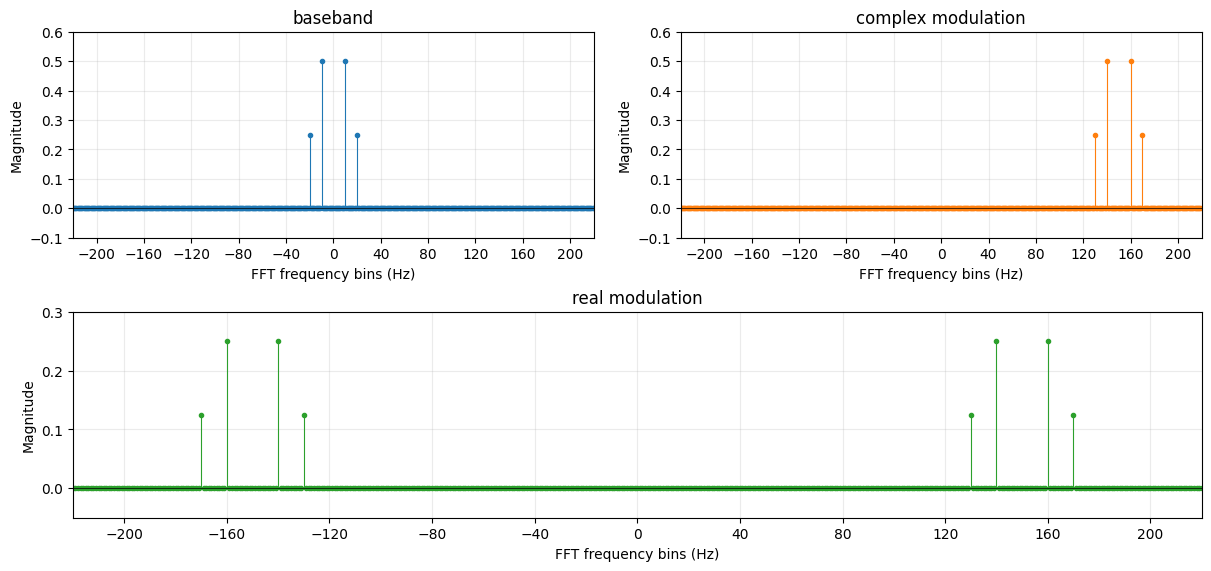

复调制解调误差： 2.5065770579757977e-16


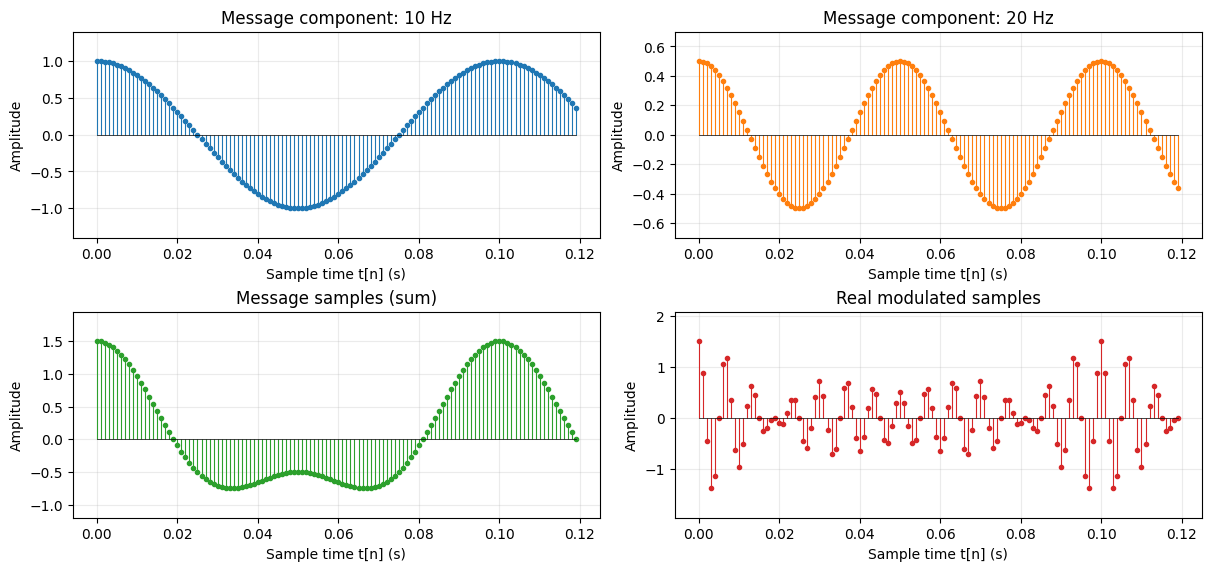

[<Axes: title={'center': 'Message component: 10 Hz'}, xlabel='Sample time t[n] (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Message component: 20 Hz'}, xlabel='Sample time t[n] (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Message samples (sum)'}, xlabel='Sample time t[n] (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Real modulated samples'}, xlabel='Sample time t[n] (s)', ylabel='Amplitude'>]

In [14]:
fs=1000; N=1000; t=np.arange(N)/fs; fc=150
message=np.cos(2*np.pi*10*t)+0.5*np.cos(2*np.pi*20*t)
complex_mod=message*np.exp(2j*np.pi*fc*t); real_mod=message*np.cos(2*np.pi*fc*t)
f=np.fft.fftshift(np.fft.fftfreq(N,1/fs))
graph(f,{'baseband':abs(np.fft.fftshift(np.fft.fft(message)))/N,
         'complex modulation':abs(np.fft.fftshift(np.fft.fft(complex_mod)))/N,
         'real modulation':abs(np.fft.fftshift(np.fft.fft(real_mod)))/N},'FFT frequency bins (Hz)','Magnitude',kind='discrete',xlim=(-220,220))
recovered_complex=complex_mod*np.exp(-2j*np.pi*fc*t)
print('复调制解调误差：',err(recovered_complex,message))
graph(t[:120],{'Message component: 10 Hz':np.cos(2*np.pi*10*t[:120]),
    'Message component: 20 Hz':0.5*np.cos(2*np.pi*20*t[:120]),
    'Message samples (sum)':message[:120], 'Real modulated samples':real_mod[:120]},
    'Sample time t[n] (s)',kind='discrete')

**观察与应用：** 广播和无线通信把不同消息搬到不同载波频段，便于共用信道。这里 fc 和消息频率都落在 FFT 栅格上；真实接收还需要同步、滤波与噪声处理。

## 实验 14：周期冲激谱与有限观测窗

**要理解什么：** 理解无限周期的理想冲激谱，与有限时长观测到的窄峰之间的关系。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\widetilde{x}(t)=\sum_ka_ke^{jk\omega_0t}\quad\Longrightarrow\quad\boxed{\widetilde{X}(\omega)=2\pi\sum_{k=-\infty}^{+\infty}a_k\delta(\omega-k\omega_0)}
\end{gathered}
$$

**符号与代码怎样对应：** 取单位余弦，a±1=1/2，所以理想正负两条冲激权重均为 π。右图用有限竖杆示意权重；左图对有限记录做补零 FFT，并乘 1/fs 近似连续变换的频率采样，只展示正频率峰附近。

**怎样读图、怎样判断结果：** 观察时长从 0.5 增至 2 秒时峰变高变窄，位置不变。有限峰不是 δ 本身，不能把峰高和理想权重 π 直接比较；实验只演示理想模型与观测窗的联系。

**先预测，再改参数：** 只增大补零倍数，预测点更密但由原观测时长决定的主瓣宽度不变。

**本例设置与适用范围：**

对应分析第九节。无限周期信号的变换是冲激列，权重 $2\pi a_k$；有限观测得到窄峰，不是数值上的无限高冲激。

左图以散点表示补零 FFT 的离散频率采样；理想的连续时间有限窗频谱本身是连续函数。右图竖杆仅示意广义函数冲激的**权重**，不是普通函数的有限峰高。

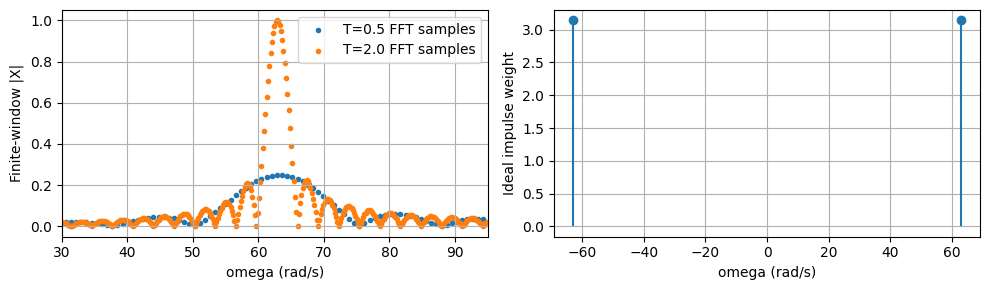

In [15]:
fs=1000.; f0=10.
fig,axes=plt.subplots(1,2,figsize=(10,3))
for T in [0.5,2.]:
    N=int(T*fs); t=np.arange(N)/fs; x=np.cos(2*np.pi*f0*t)
    f=np.fft.fftshift(np.fft.fftfreq(N*16,1/fs))
    X=np.fft.fftshift(np.fft.fft(x,N*16))/fs
    mask=(2*np.pi*f>=30)&(2*np.pi*f<=95)
    axes[0].scatter(2*np.pi*f[mask],abs(X[mask]),s=9,label=f'T={T} FFT samples')
axes[0].set(xlim=(30,95),xlabel='omega (rad/s)',ylabel='Finite-window |X|'); axes[0].legend()
axes[1].stem([-2*np.pi*f0,2*np.pi*f0],[np.pi,np.pi],basefmt=' ')
axes[1].set(xlabel='omega (rad/s)',ylabel='Ideal impulse weight')
plt.tight_layout(); plt.show()

**观察与应用：** 观察时间越长，峰越窄、越高，但理想谱线应以权重而非高度理解。用于区分机械振动中的周期分量；有限观察窗造成的峰宽不一定意味着物理频率在波动。

## 实验 15：DFT、IDFT、FFT 奇偶分解与速度

**要理解什么：** 理解 DFT 的数学定义、逆变换归一化与 FFT 的奇偶拆分。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N}} \\[6pt]
\boxed{x[n]=\frac1N\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}} \\[6pt]
\boxed{X[k]=E[k]+W_N^kO[k]},\quad\boxed{X[k+N/2]=E[k]-W_N^kO[k]}
\end{gathered}
$$

**符号与代码怎样对应：** `direct` 用指数矩阵逐项计算定义；`fast` 调库 FFT；`E,O` 分别变换偶数与奇数位置的输入，`W` 是旋转因子，`combined` 按两条合并公式拼接。

**怎样读图、怎样判断结果：** 直接 DFT、FFT、奇偶合并三者应一致，IDFT 应恢复 x。图中 m 是子序列编号、k 是频点编号；FFT 没有改变频谱含义。单次计时仅示意，不能作为严格速度评测。

**先预测，再改参数：** 把 N 改为另一个较小的偶数，重做比较；不要为了测速构造过大的 N×N 显式矩阵。

**本例设置与适用范围：**

对应分析第十节。直接构造 DFT 矩阵与 FFT 对比，并实现一层基 2 奇偶合并；FFT 是相同变换的高效算法。

DFT/FFT 与奇偶合并误差： 2.613918746553251e-12 1.0658141036401503e-14
IDFT 恢复误差： 6.181158509343568e-16
本次直接DFT（含矩阵构造）0.002406s，FFT 0.000113s；单次时间只作示意
理论计算量趋势：N^2 对比 N log2 N：
128 16384 896.0
1024 1048576 10240.0
8192 67108864 106496.0


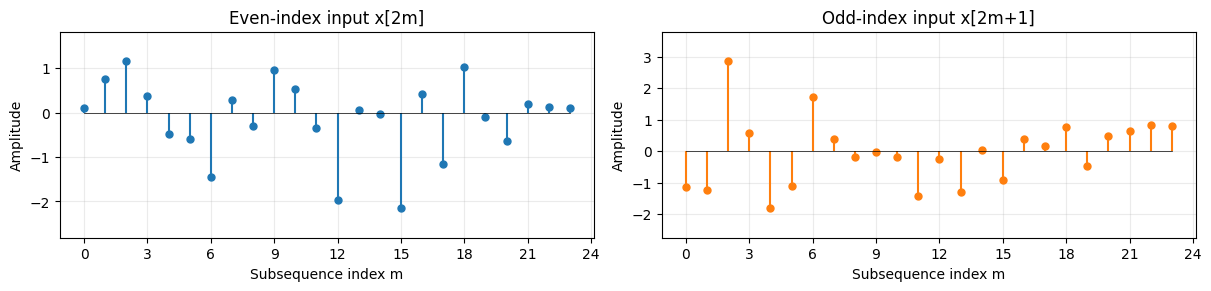

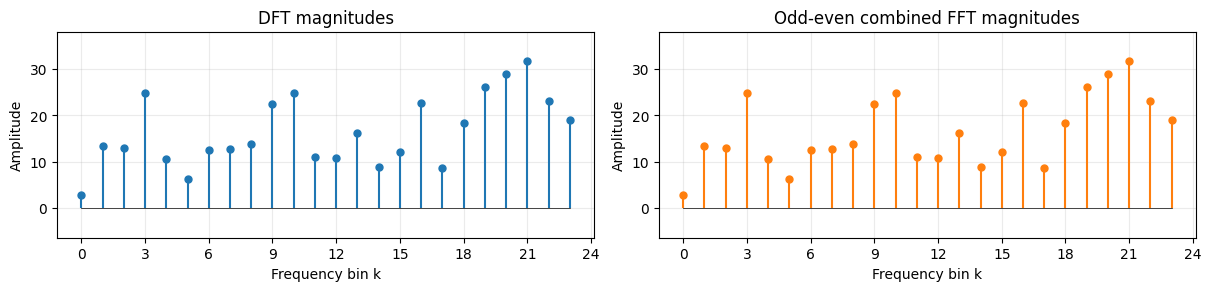

[<Axes: title={'center': 'DFT magnitudes'}, xlabel='Frequency bin k', ylabel='Amplitude'>,
 <Axes: title={'center': 'Odd-even combined FFT magnitudes'}, xlabel='Frequency bin k', ylabel='Amplitude'>]

In [16]:
from time import perf_counter
N=256; x=rng.normal(size=N); n=np.arange(N); k=n[:,None]
start=perf_counter(); direct=np.exp(-2j*np.pi*k*n/N)@x; t_direct=perf_counter()-start
start=perf_counter(); fast=np.fft.fft(x); t_fft=perf_counter()-start
E=np.fft.fft(x[::2]); O=np.fft.fft(x[1::2]); W=np.exp(-2j*np.pi*np.arange(N//2)/N)
combined=np.r_[E+W*O,E-W*O]
print('DFT/FFT 与奇偶合并误差：',err(direct,fast),err(combined,fast))
print('IDFT 恢复误差：',err(np.fft.ifft(fast),x))
print(f'本次直接DFT（含矩阵构造）{t_direct:.6f}s，FFT {t_fft:.6f}s；单次时间只作示意')
assert np.allclose(direct,fast) and np.allclose(combined,fast)
print('理论计算量趋势：N^2 对比 N log2 N：')
for size in [128,1024,8192]: print(size,size**2,size*np.log2(size))
graph(np.arange(24),{'Even-index input x[2m]':x[::2][:24],
    'Odd-index input x[2m+1]':x[1::2][:24]},'Subsequence index m',kind='discrete')
graph(np.arange(24),{'DFT magnitudes':abs(direct[:24]),
    'Odd-even combined FFT magnitudes':abs(combined[:24])},'Frequency bin k',kind='discrete')

**观察与应用：** FFT 支持实时频谱和大规模滤波。单次计时受初始化与硬件影响，不能据此精确估计算法常数；本例只对 N=256 显式生成矩阵，避免内存爆炸。

## 实验 16：卷积定理、循环混叠与系统辨识

**要理解什么：** 理解卷积在频域成为乘法，同时理解频响反推为什么需要足够激励。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{y(t)=x(t)*h(t)\quad\Longleftrightarrow\quad Y(\omega)=X(\omega)H(\omega)} \\[6pt]
\boxed{H(\omega)=\frac{Y(\omega)}{X(\omega)}},\quad X(\omega)\ne0
\end{gathered}
$$

**符号与代码怎样对应：** 代码验证离散有限序列对应关系：先补零至 L≥Nx+Nh−1，再做 DFT 相乘与逆变换。`linear` 为直接卷积，`via_fft` 为频域结果；不补零的 `wrong` 是循环卷积。辨识部分用噪声测量 Y/X，并以 Y*conj(X)/(|X|²+λ) 作正则近似，后者是应用方法而非笔记原等式。

**怎样读图、怎样判断结果：** 补零后卷积结果应一致，未补零出现尾部回绕误差；输入弱激励处直接相除可能放大噪声。正则化 RMSE 通常更好，但会引入偏差，不能恢复输入完全没激励的频段。

**先预测，再改参数：** 改变 λ，比较抑噪和估计偏差；将输入改成单频，思考为何不能可靠识别整条频响。

**本例设置与适用范围：**

对应分析八、性质第九节。离散线性卷积需补零至至少 $N_x+N_h-1$。频域估计 $H=Y/X$ 在输入能量弱处不稳定，采用 $Y X^*/(|X|^2+\lambda)$ 正则化。

补零误差： 6.661338147750939e-16 未补零首段误差： 0.1560543936470036
直接相除/正则估计复频响 RMSE： 4.170103527091 0.46131530551162087


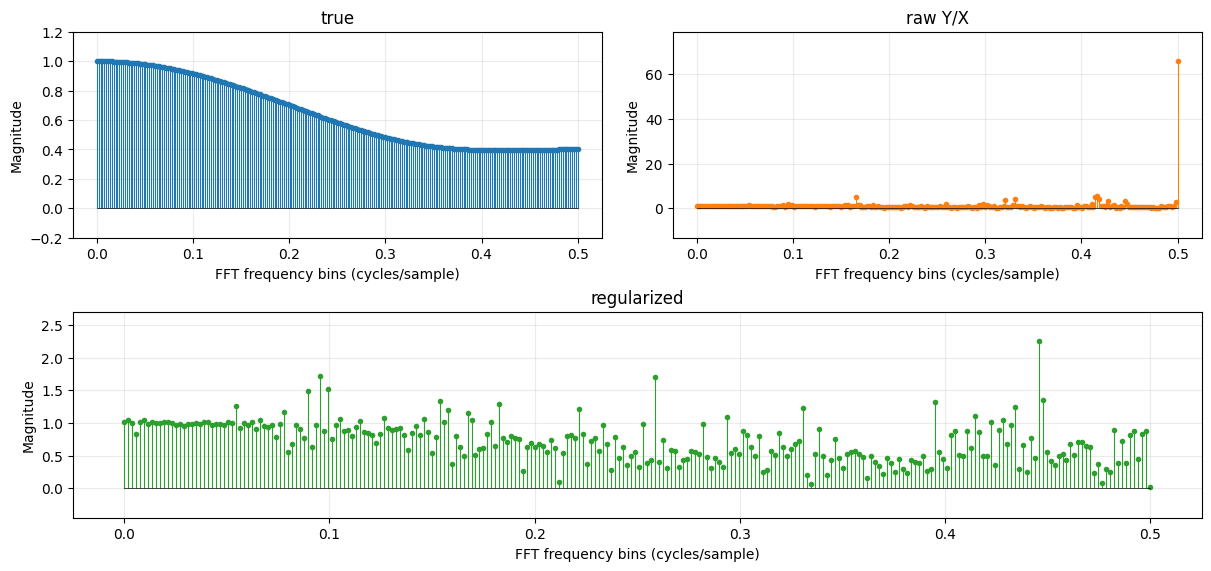

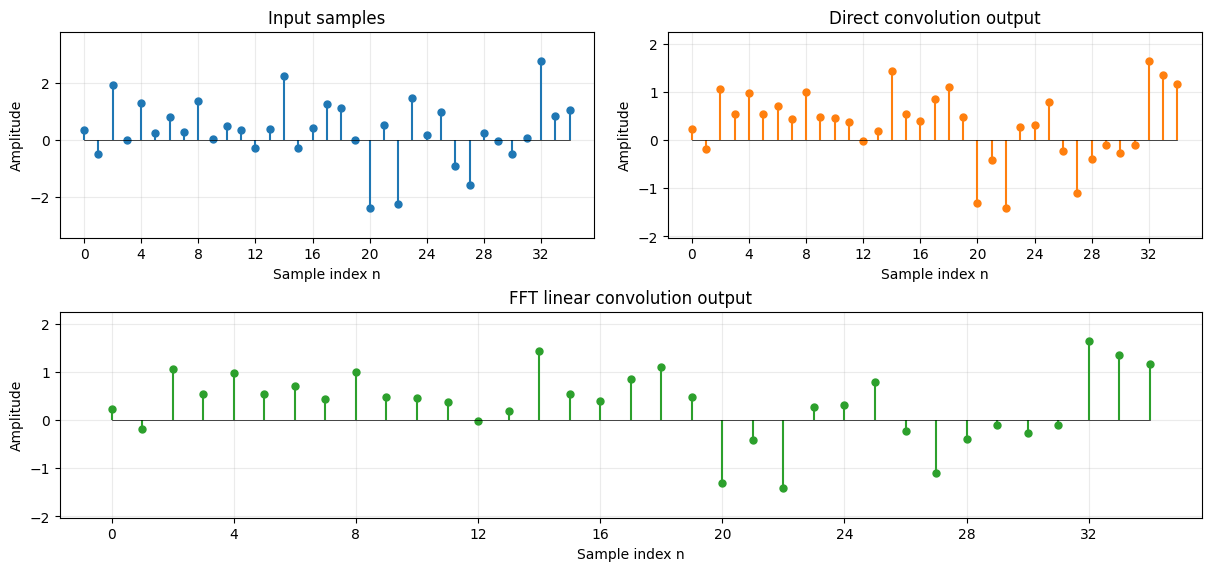

[<Axes: title={'center': 'Input samples'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'Direct convolution output'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'FFT linear convolution output'}, xlabel='Sample index n', ylabel='Amplitude'>]

In [17]:
x=rng.normal(size=128); h=np.array([0.6,0.3,0.1]); L=len(x)+len(h)-1
linear=np.convolve(x,h)
via_fft=np.fft.irfft(np.fft.rfft(x,L)*np.fft.rfft(h,L),n=L)
assert np.allclose(linear,via_fft)
wrong=np.fft.irfft(np.fft.rfft(x)*np.fft.rfft(h,len(x)),n=len(x))
print('补零误差：',err(linear,via_fft),'未补零首段误差：',err(linear[:len(x)],wrong))
# 用低频占优的探测信号说明弱激励频段的问题。
probe=signal.lfilter(np.ones(12)/12,[1],rng.normal(size=512))
y=np.convolve(probe,h); L=len(y)
X=np.fft.rfft(probe,L); Y=np.fft.rfft(y+0.02*rng.normal(size=L),L)
Htrue=np.fft.rfft(h,L); lam=0.05
raw=Y/(X+1e-15); reg=Y*X.conj()/(abs(X)**2+lam)
print('直接相除/正则估计复频响 RMSE：',np.sqrt(np.mean(abs(raw-Htrue)**2)),np.sqrt(np.mean(abs(reg-Htrue)**2)))
f=np.fft.rfftfreq(L)
graph(f,{'true':abs(Htrue),'raw Y/X':abs(raw),'regularized':abs(reg)},'FFT frequency bins (cycles/sample)','Magnitude',kind='discrete')
graph(np.arange(35),{'Input samples':x[:35],'Direct convolution output':linear[:35],
    'FFT linear convolution output':via_fft[:35]},kind='discrete')

**观察与应用：** 卷积可转成快速频域乘法；测量扬声器或传感器频响时，需要足够宽带的探测信号。正则化能抑制弱激励处噪声放大，但也会带来偏差，不能恢复完全缺失的信息。

## 实验 17：实际例子：频域降噪、泄漏与采样限制

**要理解什么：** 综合理解：滤波就是给不同频率不同权重，观察窗与采样又会限制频谱解读。

**要验证的数学形式（对照[原笔记](../../../傅里叶.md)）：**

$$
\begin{gathered}
\boxed{Y(\omega)=X(\omega)H(\omega)} \\[6pt]
 H(f)=\begin{cases}1,&|f|<60\ \mathrm{Hz}\\0,&\text{其他}\end{cases} \\[6pt]
 f_{\mathrm{alias}}=f-mf_s
\end{gathered}
$$

**符号与代码怎样对应：** 前一个等式来自笔记卷积定理；硬截止频带与混叠关系是其应用扩展。输入分解为 20Hz 有用信号、180Hz 干扰与随机噪声；代码保留低于 60Hz 的 FFT 频点再逆变换。另用 20.3Hz 比较观测窗泄漏。

**怎样读图、怎样判断结果：** 时域分量相加得到 noisy，滤波后 RMSE 应下降；窗函数比较中 Hann 旁瓣较低而主瓣变宽。820Hz 与 −180Hz 在 1000Hz 采样下样本相同，打印差应接近零，说明混叠后无法唯一辨认原频率。

**先预测，再改参数：** 把截止频率降至 10Hz，预测连有用的 20Hz 也被去掉；再恢复。频域硬截断按整段周期记录处理，不能直接当成实时因果实现。

**本例设置与适用范围：**

综合应用。用已知通带保留 20 Hz 信号，去掉 180 Hz 干扰；比较窗函数与非整周期频率的泄漏。

滤波前后 RMSE： 0.46592956842266264 0.06689168622409873


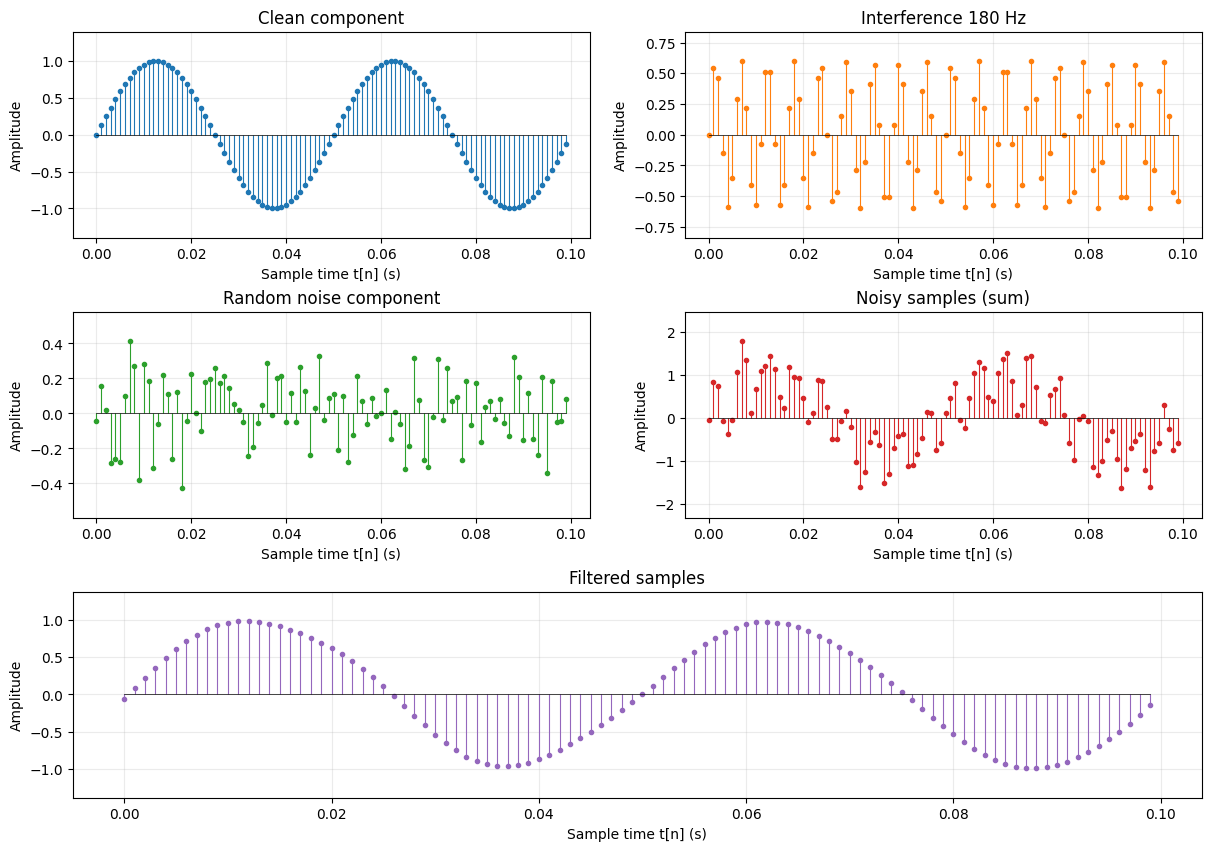

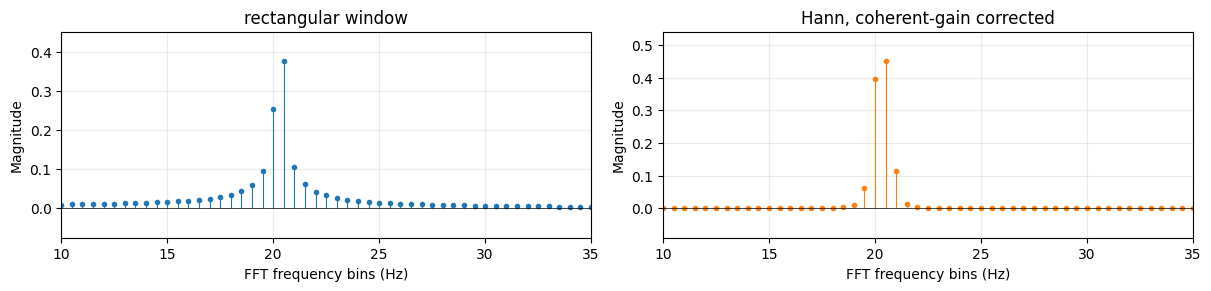

820Hz 与 -180Hz 的采样差： 1.990019260489362e-12


In [18]:
fs=1000.; N=2000; t=np.arange(N)/fs
clean=np.sin(2*np.pi*20*t); interference=0.6*np.sin(2*np.pi*180*t)
noise=0.2*rng.normal(size=N); noisy=clean+interference+noise
f=np.fft.rfftfreq(N,1/fs); X=np.fft.rfft(noisy)
filtered=np.fft.irfft(X*(f<60),n=N)
print('滤波前后 RMSE：',np.sqrt(np.mean((noisy-clean)**2)),np.sqrt(np.mean((filtered-clean)**2)))
view=slice(0,100)
graph(t[view],{'Clean component':clean[view],'Interference 180 Hz':interference[view],
    'Random noise component':noise[view],'Noisy samples (sum)':noisy[view],
    'Filtered samples':filtered[view]},'Sample time t[n] (s)',kind='discrete')
x=np.sin(2*np.pi*20.3*t); win=np.hanning(N)
graph(f,{'rectangular window':abs(np.fft.rfft(x))/N,'Hann, coherent-gain corrected':abs(np.fft.rfft(x*win))/sum(win)},'FFT frequency bins (Hz)','Magnitude',kind='discrete',xlim=(10,35))
# 采样混叠：fs=1000 下的 820Hz 与 -180Hz 正弦样本相同。
print('820Hz 与 -180Hz 的采样差：',err(np.sin(2*np.pi*820*t),np.sin(-2*np.pi*180*t)))

**观察与应用：** 可去掉已知高频干扰；理想硬截频对整段记录做周期处理，边界可能振铃，实时应用应设计因果滤波器。Hann 窗降低旁瓣但加宽主瓣；补零只加密频谱显示，不能提高由观测时长决定的真实分辨能力。采样前还需限制带宽，混叠后的频率无法仅靠数字滤波恢复。

## 实验记录

每次选一个参数，记录：原值、新值、图像变化、指标变化、可以解决的实际问题、模型的适用条件。先预测结果，再运行验证。